In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import math
#from IPython.core.display import display, HTML
#display(HTML("<style>.container { width:100% !important; }</style>"))
#display(HTML("<style>.output { height:auto !important; }</style>"))
import pandas as pd
import numpy as np
import datetime as dt
pd.set_option('display.max_rows', 1000)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
import sys
import configparser
import os
from scipy.fft import rfft,rfftfreq, irfft
freq=.1
interval=500
n_points=1
x=[t/n_points for t in range(int(interval*n_points))] 
y=[2*np.sin(2*np.pi*freq*t) +0.3*np.sin(2*np.pi*.1*freq*t) for t in x]
yf = rfft(y)
#yf = rfft(data_t['Продольный наклон'].tolist())
abs_yf=[np.abs(yf)/len(yf) for y in yf] 
xf = rfftfreq(len(y), 1 / n_points)
y=irfft(yf)
print('len=',len(y),len(yf),len(y),interval*n_points)
sys.path.append('C:\\Users\\victor.maltsev\\Projects\\Советчик\\Rapsberry_adviser\\последняя версия')
#import functions_recommendations as funrec
#import draws
#config.read('C:\\Users\\victor.maltsev\\Projects\\Советчик\\Rapsberry_adviser\\последняя версия\\config.txt', encoding='cp1251')
mainpath='C:\\Users\\victor.maltsev\\Тестирование\\Айхал\\КС_159\\route1\\'
os.chdir(mainpath)

#data_t=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\raw_folder\\1_w.csv',sep=';',encoding='cp1251')
data_t=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Айхал\\КС_159\\route1\\3_w.csv',sep=';',encoding='cp1251')
print('len(data_t=',len(data_t))


data_t['Продольный наклон']=data_t['Продольный наклон'].interpolate(direction='both')
data_t['Ускорение по оси X']=data_t['Ускорение по оси X'].interpolate(direction='both')
data_t['Ускорение по оси Y']=data_t['Ускорение по оси Y'].interpolate(direction='both')
data_t['Ускорение по оси Z']=data_t['Ускорение по оси Z'].interpolate(direction='both')
data_t["Прод_нак"] =data_t.apply(lambda x: np.arctan(-x["Ускорение по оси Z"]/np.sqrt(x["Ускорение по оси X"]**2+x["Ускорение по оси Y"]**2))*180/np.pi,axis=1)-0.9
data_t['Timestamp']=data_t['Timestamp'].astype('datetime64[ns]').dt.round('1s')
n_points=1
interval=int(len(data_t)/4)
print(interval)
#display(data_t[['Timestamp','Продольный наклон']])
yf = rfft(data_t['Прод_нак'].tolist())
#yf = rfft(data_t['Продольный наклон'].tolist())
abs_yf=[np.abs(yf)/len(yf) for y in yf] 
xf = rfftfreq(len(data_t), 1 / n_points)

ind_=min([i for i in range(len(xf)) if xf[i]>=0.2])

yf[ind_:]=0
abs_yf=[np.abs(y)/len(yf) for y in yf] 
data_t["Прод_нак_fft"]=irfft(yf)

fig = make_subplots(specs=[[{"secondary_y": True}]])

#fig.add_trace(go.Bar(x=xf[:800], y=abs_yf[:800],width=.001, name='spectr'),secondary_y=False)

#fig.update_layout(title_text='Спектр  ',width=1200,height=500)
#data["Прод_нак_fft"]=irfft(yf)
#fig.add_trace(go.Scatter(x=data_t['Timestamp'], y=data_t['Ток датчика давления, левый передний цилиндр'],mode='lines', name='давление слева'),secondary_y=False)
#fig.add_trace(go.Scatter(x=data['len'], y=data['Давление правый передний цилиндр'],mode='lines', name='давление справа'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_t['Timestamp'], y=data_t['Продольный наклон'],mode='lines', name='продольный наклон'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_t['Timestamp'], y=data_t['Прод_нак'],mode='lines', name='проднак'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_t['Timestamp'], y=data_t['Прод_нак_fft'],mode='lines', name='проднак_fft'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_t['Timestamp'], y=data_t['Высота'],mode='lines', name='Высота'),secondary_y=False)

#fig.add_trace(go.Scatter(x=[i for i in range(len(mes))], y=mes,mode='lines', name='измерения веса слитка'),secondary_y=False)
fig.update_layout(title_text='Наклоны и высота ',width=1100,height=500)
fig.show()


### Проблема профиля дороги

In [ ]:
import folium
from folium import plugins
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np

data_1=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\test\\route1\\1_w.csv',sep=';',encoding='cp1251')
data_1['xy']=data_1.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

data_2=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\5_w.csv',sep=';',encoding='cp1251')
data_2['xy']=data_2.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

data_1["Продольный наклон"] = np.arctan(-data_1["Ускорение по оси Z"]/np.sqrt(data_1["Ускорение по оси X"]**2+data_1["Ускорение по оси Y"]**2))*180/np.pi
data_2["Продольный наклон"] = np.arctan(-data_2["Ускорение по оси Z"]/np.sqrt(data_2["Ускорение по оси X"]**2+data_2["Ускорение по оси Y"]**2))*180/np.pi
m = folium.Map (data_1.loc[0,'xy'], zoom_start = 13)
title_html = '''<h3 align="center" style="font-size:21px"><b>{}</b></h3>'''.format('Рейсы самосвала КС 1982')

m.get_root().html.add_child(folium.Element(title_html)) 

route = folium.PolyLine (list(data_1['xy']),вес = 3, color = 'green', непрозрачность = 0.8).add_to (m)
route = folium.PolyLine (list(data_2['xy']),вес = 3, color = 'blue', непрозрачность = 0.8).add_to (m)

display(m)
m.save('map1989.html')

fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Продольный наклон'],mode='lines', name='продольный наклон_1'),secondary_y=True)
#fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Продольный наклон'],mode='lines', name='продольный наклон_2'),secondary_y=True)

fig.update_layout(title_text='Профиль дороги ',width=1100,height=500)
fig.show()



### Спектр гармонического сигнала

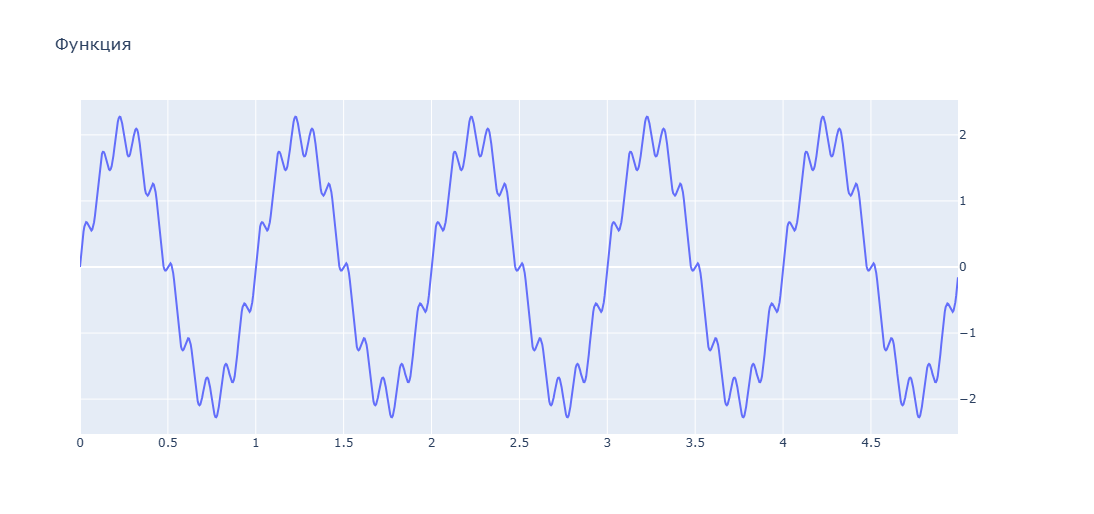

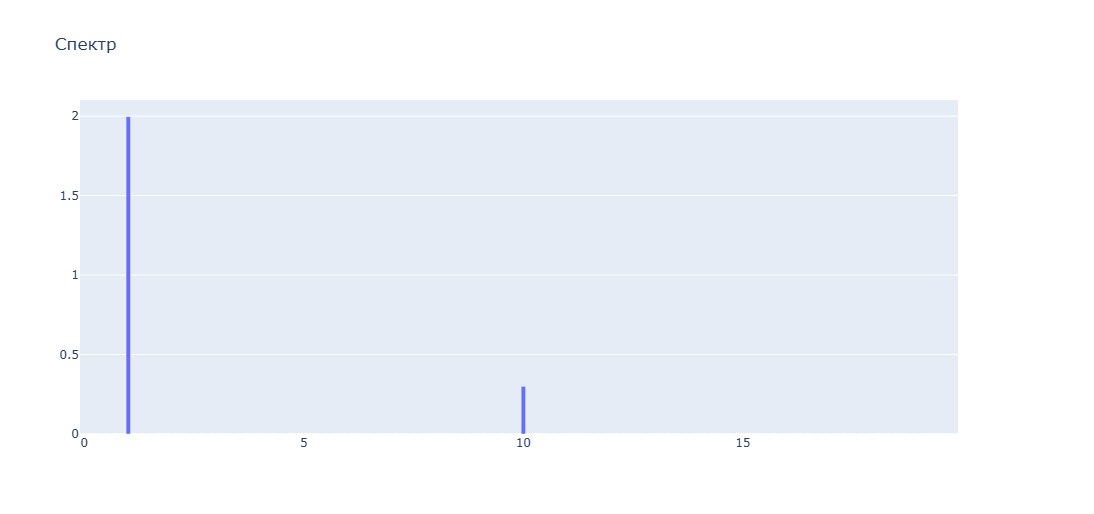

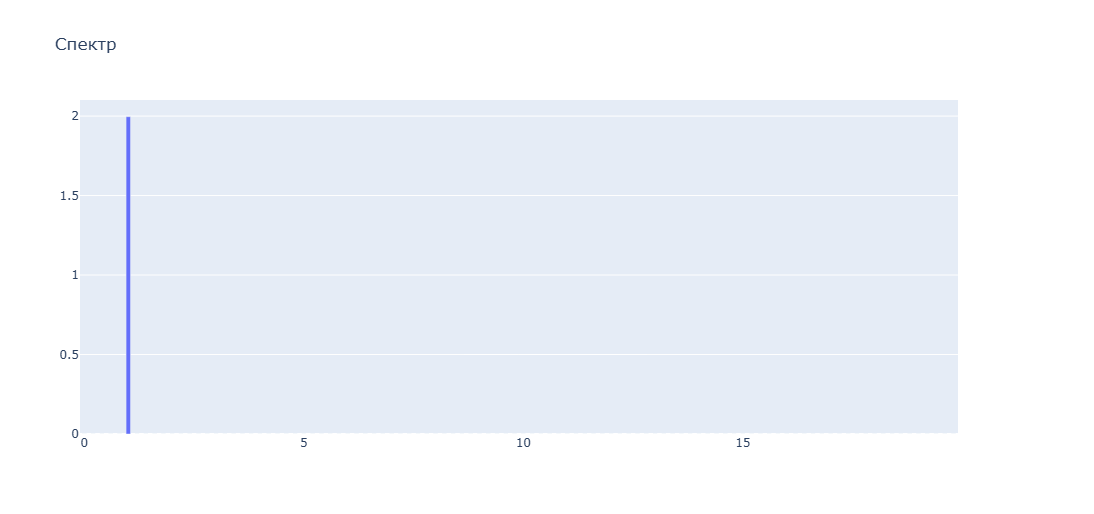

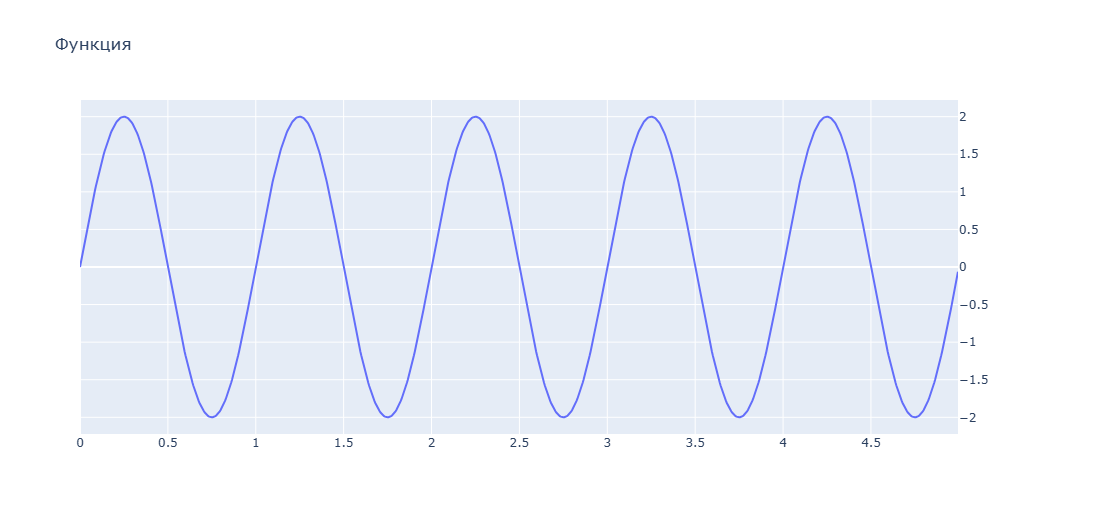

In [1]:
import math
import pandas as pd
import numpy as np
from scipy.fft import rfft,rfftfreq, irfft
import plotly.graph_objects as go
from plotly.subplots import make_subplots

freq=1
interval=5
n_points=200
x=[t/n_points for t in range(int(interval*n_points))] 
y=[2*np.sin(2*np.pi*freq*t) +0.3*np.sin(2*np.pi*10*freq*t) for t in x]

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=x, y=y,mode='lines', name='Гармоническая функция'),secondary_y=True)
fig.update_layout(title_text='Функция ',width=1100,height=500)
fig.show()

yf = rfft(y)
abs_yf=[np.abs(i)/len(yf) for i in yf]
xf = rfftfreq(len(y), 1 / n_points)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=xf[:100], y=abs_yf[:100],width=.1, name='spectr'),secondary_y=False)
fig.update_layout(title_text='Спектр  ',width=1200,height=500)
fig.show() 

ind=min([i for i in range(len(xf)) if xf[i]>=10])
yf[ind:]=0
abs_yf=[np.abs(i)/len(yf) for i in yf]

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=xf[:100], y=abs_yf[:100],width=.1, name='spectr'),secondary_y=False)
fig.update_layout(title_text='Спектр  ',width=1200,height=500)
fig.show() 

y=irfft(yf)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=x, y=y,mode='lines', name='Гармоническая функция'),secondary_y=True)
fig.update_layout(title_text='Функция ',width=1100,height=500)
fig.show()


### Спектральный анализ продольного наклона

In [ ]:
import pandas as pd
from scipy.fft import rfft,rfftfreq, irfft
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

data_1=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\test\\route1\\1_w.csv',sep=';',encoding='cp1251')
data_1['xy']=data_1.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

if len(data_1)%2==0:
   pass
else:
    data_1.drop(0,inplace=True)
    data_1.reset_index(drop=True,inplace=True)


#data_2=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\5_w.csv',sep=';',encoding='cp1251')
#data_2['xy']=data_2.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

#if len(data_2)%2==0:
#    pass
#else:
#    data_2.drop(0,inplace=True)
#    data_2.reset_index(drop=True,inplace=True)
    
data_1["Продольный наклон"] = np.arctan(-data_1["Ускорение по оси Z"]/np.sqrt(data_1["Ускорение по оси X"]**2+data_1["Ускорение по оси Y"]**2))*180/np.pi
#data_2["Продольный наклон"] = np.arctan(-data_2["Ускорение по оси Z"]/np.sqrt(data_2["Ускорение по оси X"]**2+data_2["Ускорение по оси Y"]**2))*180/np.pi

fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Продольный наклон'],mode='lines', name='продольный наклон_1'),secondary_y=True)
#fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Продольный наклон'],mode='lines', name='продольный наклон_2'),secondary_y=True)

fig.update_layout(title_text='Профиль дороги ',width=1100,height=500)
fig.show()

n_points=10

yf = rfft(data_1['Продольный наклон'])
abs_yf=[np.abs(i)/len(yf) for i in yf] 
xf = rfftfreq(len(data_1), 1 / n_points)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=xf[:100], y=abs_yf[:100],width=.01, name='spectr'),secondary_y=False)

fig.update_layout(title_text='Спектр_1 ',width=1200,height=500)
fig.show()

ind_=min([i for i in range(len(xf)) if xf[i]>=2.0])

yf[ind_:]=0
abs_yf=[np.abs(y)/len(yf) for y in yf] 
#print('4  len(data_2)=',len(data_2))
data_1["Прод_нак_fft"]=irfft(yf)
prod_nak_fft_1=data_1["Прод_нак_fft"].tolist()
#yf = rfft(data_2['Продольный наклон'])
#abs_yf=[np.abs(i)/len(yf) for i in yf] 
#xf = rfftfreq(len(data_2), 1 / n_points)
#ind_=min([i for i in range(len(xf)) if xf[i]>=0.5])
#yf[ind_:]=0
#abs_yf=[np.abs(y)/len(yf) for y in yf] 
#data_2["Прод_нак_fft"]=irfft(yf)
#prod_nak_fft_2=data_2["Прод_нак_fft"].tolist()
                                                                                                                                                                                                                                                                                                                                                                                                       
fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Продольный наклон'],mode='lines', name='продольный наклон_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Прод_нак_fft'],mode='lines', name='продольный наклон_1_fft'),secondary_y=True)


#fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Продольный наклон'],mode='lines', name='продольный наклон_2'),secondary_y=True)
#fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Прод_нак_fft'],mode='lines', name='продольный наклон_2_fft'),secondary_y=True)

fig.update_layout(title_text='Профиль дороги отфильтрованный',width=1100,height=500)
fig.show()
fig.write_html("Профиль дороги.html")
data_1["Высота_fft"] = data_1.loc[0,"Высота"]
data_1=data_1.copy()
for i in range(1, len(data_1)):
    #print('data_1.loc[i-1, "Высота_fft"]=',round(data_1.loc[i-1, "Высота_fft"],2),' data_1["len"].iloc[i]=',data_1["len"].iloc[i],' data_1["len"].iloc[i-1]=',data_1["len"].iloc[i-1],'data_1["Прод_нак_fft"].iloc[i-1]=',round(data_1["Прод_нак_fft"].iloc[i-1],2),
    #     'tg=',round(np.tan(data_1["Прод_нак_fft"].iloc[i-1]*np.pi/180.),3),' +=',(data_1["len"].iloc[i] - data_1["len"].iloc[i-1]) * np.tan(data_1["Прод_нак_fft"].iloc[i-1]*np.pi/180.))
    data_1.loc[i, "Высота_fft"] = data_1.loc[i-1, "Высота_fft"] + (data_1["len"].iloc[i] - data_1["len"].iloc[i-1]) * np.tan((data_1["Прод_нак_fft"].iloc[i-1]-0.8)*np.pi/180.)   
#data_2["Высота_fft"] = data_2.loc[0,"Высота"]
#for i in range(1, len(data_2)):
    #print('row 219 df.loc[i-1, "Высота"]=',df.loc[i-1, "Высота"],' df["len"].iloc[i]=',df["len"].iloc[i],' df["len"].iloc[i-1]=',df["len"].iloc[i-1],'df["Продольный наклон"].iloc[i-1]=',df["Продольный наклон"].iloc[i-1])
#    data_2.loc[i, "Высота_fft"] = data_2.loc[i-1, "Высота_fft"] + float(data_2["len"].iloc[i] - data_2["len"].iloc[i-1]) * np.tan(data_2["Прод_нак_fft"].iloc[i-1]*np.pi/180.)   

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Высота'],mode='lines', name='Высота_1'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Высота_fft'],mode='lines', name='Высота_1_fft'),secondary_y=False)
#fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Высота'],mode='lines', name='Высота_2'),secondary_y=False)
#fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Высота_fft'],mode='lines', name='Высота_2_fft'),secondary_y=False)
fig.update_layout(title_text='Проверка профиля дороги высотой',width=1100,height=500)
fig.show()
fig.write_html("Проверка высотой.html")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\test\\route1\\1_w.csv'

## Спектральный анализ поперечного наклона

In [ ]:
import pandas as pd
from scipy.fft import rfft,rfftfreq, irfft
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots


data_1=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\1_w.csv',sep=';',encoding='cp1251')
data_1['xy']=data_1.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

if len(data_1)%2==0:
   pass
else:
    data_1.drop(0,inplace=True)
    data_1.reset_index(drop=True,inplace=True)


data_2=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\5_w.csv',sep=';',encoding='cp1251')
data_2['xy']=data_2.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

if len(data_2)%2==0:
    pass
else:
    data_2.drop(0,inplace=True)
    data_2.reset_index(drop=True,inplace=True)

data_1["Поперечный наклон"] = np.arctan(-data_1["Ускорение по оси X"]/np.sqrt(data_1["Ускорение по оси Z"]**2+data_1["Ускорение по оси Y"]**2))*180/np.pi
data_2["Поперечный наклон"] = np.arctan(-data_2["Ускорение по оси X"]/np.sqrt(data_2["Ускорение по оси Z"]**2+data_2["Ускорение по оси Y"]**2))*180/np.pi

fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Поперечный наклон'],mode='lines', name='Поперечный наклон_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Поперечный наклон'],mode='lines', name='Поперечный наклон_2'),secondary_y=True)

fig.update_layout(title_text='Поперечный профиль дороги ',width=1100,height=500)
fig.show()

n_points=10

yf = rfft(data_1['Поперечный наклон'])
abs_yf=[np.abs(i)/len(yf) for i in yf] 
xf = rfftfreq(len(data_1), 1 / n_points)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=xf[:100], y=abs_yf[:100],width=.01, name='spectr'),secondary_y=False)

fig.update_layout(title_text='Спектр_1 ',width=1200,height=500)
fig.show()

ind_=min([i for i in range(len(xf)) if xf[i]>=0.5])

yf[ind_:]=0
abs_yf=[np.abs(y)/len(yf) for y in yf] 
data_1["Поп_нак_fft"]=irfft(yf)
pop_nak_fft_1=data_1["Поп_нак_fft"].tolist()
yf = rfft(data_2['Поперечный наклон'])
abs_yf=[np.abs(i)/len(yf) for i in yf] 
xf = rfftfreq(len(data_2), 1 / n_points)
ind_=min([i for i in range(len(xf)) if xf[i]>=0.5])
yf[ind_:]=0
abs_yf=[np.abs(y)/len(yf) for y in yf] 
data_2["Поп_нак_fft"]=irfft(yf)
pop_nak_fft_2=data_2["Поп_нак_fft"].tolist()
fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Поперечный наклон'],mode='lines', name='Поперечный наклон_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Поп_нак_fft'],mode='lines', name='Поперечный наклон_1_fft'),secondary_y=True)


fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Поперечный наклон'],mode='lines', name='Поперечный наклон_2'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_2['len'], y=data_2['Поп_нак_fft'],mode='lines', name='Поперечный наклон_2_fft'),secondary_y=True)

fig.update_layout(title_text='Поперечный профиль дороги отфильтрованный',width=1100,height=500)
fig.show()
fig.write_html("Профиль поперечного наклона.html")


### Датчики давления

In [ ]:
import pandas as pd
from scipy.fft import rfft,rfftfreq, irfft
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots


data_1=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\1_w.csv',sep=';',encoding='cp1251')
data_1['xy']=data_1.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

if len(data_1)%2==0:
   pass
else:
    data_1.drop(0,inplace=True)
    data_1.reset_index(drop=True,inplace=True)


data_2=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\5_w.csv',sep=';',encoding='cp1251')
data_2['xy']=data_2.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

if len(data_2)%2==0:
    pass
else:
    data_2.drop(0,inplace=True)
    data_2.reset_index(drop=True,inplace=True)

n_points=10
tags=['Давление левый передний цилиндр','Давление правый передний цилиндр','Давление левый задний цилиндр','Давление правый задний цилиндр']
for tag in tags:
    yf = rfft(data_1[tag])
    abs_yf=[np.abs(i)/len(yf) for i in yf] 
    xf = rfftfreq(len(data_1), 1 / n_points)
    
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    fig.add_trace(go.Bar(x=xf[1:100], y=abs_yf[1:100],width=.01, name='Спектр_1 '+tag),secondary_y=False)
    
    fig.update_layout(title_text='Спектр '+tag,width=1200,height=500)
    fig.show()
    
    ind_=min([i for i in range(len(xf)) if xf[i]>=0.5])
    
    yf[:ind_]=0
    abs_yf=[np.abs(y)/len(yf) for y in yf] 
    data_1[tag+"_fft"]=irfft(yf)

#yf = rfft(data_2['Ускорение по оси Z'])
#abs_yf=[np.abs(i)/len(yf) for i in yf] 
#xf = rfftfreq(len(data_2), 1 / n_points)
#ind_=max([i for i in range(len(xf)) if xf[i]<=0.5])
#yf[:ind_]=0
#abs_yf=[np.abs(y)/len(yf) for y in yf] 
#data_2["ямы_fft"]=irfft(yf)

fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый передний цилиндр'],mode='lines', name='левый передний_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый передний цилиндр_fft'],mode='lines', name='левый передний_1_fft'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый передний цилиндр'],mode='lines', name='правый передний цилиндр_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый передний цилиндр_fft'],mode='lines', name='правый передний_1_fft'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый передний цилиндр_fft'],mode='lines', name='левый передний_1_fft'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый передний цилиндр_fft'],mode='lines', name='правый передний_1_fft'),secondary_y=True)

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый задний цилиндр'],mode='lines', name='левый задний_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый задний цилиндр_fft'],mode='lines', name='левый задний_1_fft'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый задний цилиндр'],mode='lines', name='правый задний цилиндр_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый задний цилиндр_fft'],mode='lines', name='правый задний_1_fft'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=prod_nak_fft_1,mode='lines', name='продольный наклон_1_fft'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=pop_nak_fft_1,mode='lines', name='поперечный наклон_1_fft'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=prod_nak_fft_2,mode='lines', name='продольный наклон_2_fft'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=pop_nak_fft_2,mode='lines', name='поперечный наклон_2_fft'),secondary_y=False)


fig.update_layout(title_text=tag+' отфильтрованное',width=1100,height=500)
fig.show()
fig.write_html("датчики давления.html")



### Анализ ям

In [ ]:
import pandas as pd
from scipy.fft import rfft,rfftfreq, irfft
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import sys
sys.path.append('C:\\Users\\victor.maltsev\\Projects\\Советчик\\Rapsberry_adviser\\последняя версия')
import functions_for_routes as funrou
import configparser
config= configparser.ConfigParser()
config.read('C:\\Users\\victor.maltsev\\Projects\\Советчик\\Rapsberry_adviser\\последняя версия\\config.txt', encoding='cp1251')
amper_param=int(config.get('Signals','parameter for digitizing current signals'))


critical_length_for_holes=int(config.get('Border','minimum distance between pits'))

data_1=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\1_w.csv',sep=';',encoding='cp1251')
data_1['xy']=data_1.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)
dump_code=data_1.loc[0,'Самосвал']
dump_width=float(config.get('Dumper','Dumper width '+str(dump_code)))/1000.
print('dump_code=',dump_code,' dump_width=',dump_width)

if len(data_1)%2==0:
   pass
else:
    data_1.drop(0,inplace=True)
    data_1.reset_index(drop=True,inplace=True)


data_2=pd.read_csv('C:\\Users\\victor.maltsev\\Тестирование\\Стройсервис\\КС_1982\\route2\\5_w.csv',sep=';',encoding='cp1251')
data_2['xy']=data_2.apply(lambda x:[x['Широта'],x['Долгота']],axis=1)

if len(data_2)%2==0:
    pass
else:
    data_2.drop(0,inplace=True)
    data_2.reset_index(drop=True,inplace=True)

n_points=10
tags=['Давление левый передний цилиндр','Давление правый передний цилиндр','Давление левый задний цилиндр','Давление правый задний цилиндр']
for tag in tags:
    yf = rfft(data_1[tag])
    abs_yf=[np.abs(i)/len(yf) for i in yf] 
    xf = rfftfreq(len(data_1), 1 / n_points)
    
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    fig.add_trace(go.Bar(x=xf[1:100], y=abs_yf[1:100],width=.01, name='Спектр_1 '+tag),secondary_y=False)
    
    fig.update_layout(title_text='Спектр '+tag,width=1200,height=500)
    fig.show()
    
    ind_=max([i for i in range(len(xf)) if xf[i]<=0.5])
    
    yf[:ind_]=0
    abs_yf=[np.abs(y)/len(yf) for y in yf] 
    data_1[tag+"_hole"]=irfft(yf)

#yf = rfft(data_2['Ускорение по оси Z'])
#abs_yf=[np.abs(i)/len(yf) for i in yf] 
#xf = rfftfreq(len(data_2), 1 / n_points)
#ind_=max([i for i in range(len(xf)) if xf[i]<=0.5])
#yf[:ind_]=0
#abs_yf=[np.abs(y)/len(yf) for y in yf] 
#data_2["ямы_fft"]=irfft(yf)
print(data_1.columns)
#display(data_1[['len','point','nom_point']].head(3))
lf_l=data_1[data_1['Давление левый передний цилиндр_hole']>0]['Давление левый передний цилиндр_hole'].quantile(0.5)
lf_r=data_1[data_1['Давление правый передний цилиндр_hole']>0]['Давление правый передний цилиндр_hole'].quantile(0.5)
rf_l=data_1[data_1['Давление левый задний цилиндр_hole']>0]['Давление левый задний цилиндр_hole'].quantile(0.5)
rf_r=data_1[data_1['Давление правый задний цилиндр_hole']>0]['Давление правый задний цилиндр_hole'].quantile(0.5)
print('lf_правый=',lf_l,' lf_левый=',lf_r,' rf_левый=',rf_l,' rf_правый=',rf_r)
lf=(lf_l+lf_r)/2
lr=(rf_l+rf_r)/2
data_1=funrou.pit_marking((lf_l+lf_r)/2,(rf_l+rf_r)/2,data_1,critical_length_for_holes,amper_param,dump_width)
print(data_1.columns)
#data_1=funrou.point_align(data_1,critical_length_for_holes)
print(data_1.columns)
fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый передний цилиндр'],mode='lines', name='левый передний_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый передний цилиндр_hole'],mode='lines', name='левый передний_1_hole'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый передний цилиндр_hole_'],mode='lines', name='левый передний_hole_'),secondary_y=False)

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый передний цилиндр'],mode='lines', name='правый передний цилиндр_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый передний цилиндр_hole'],mode='lines', name='правый передний_1_hole'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый передний цилиндр_hole_'],mode='lines', name='правый передний_1_hole_'),secondary_y=False)

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый задний цилиндр'],mode='lines', name='левый задний_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый задний цилиндр_hole'],mode='lines', name='левый задний_1_hole'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление левый задний цилиндр_hole_'],mode='lines', name='левый задний_1_hole_'),secondary_y=False)

fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый задний цилиндр'],mode='lines', name='правый задний цилиндр_1'),secondary_y=True)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый задний цилиндр_hole'],mode='lines', name='правый задний_1_hole'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=data_1['Давление правый задний цилиндр_hole_'],mode='lines', name='правый задний_1_hole_'),secondary_y=False)
fig.add_trace(go.Scatter(x=data_1['len'], y=prod_nak_fft_1,mode='lines', name='продольный наклон_1_fft'),secondary_y=False)
#fig.add_trace(go.Scatter(x=data_1['len'], y=pop_nak_fft_1,mode='lines', name='поперечный наклон_1_fft'),secondary_y=False)
#fig.add_trace(go.Scatter(x=data_1['len'], y=prod_nak_fft_2,mode='lines', name='продольный наклон_2_fft'),secondary_y=False)
#fig.add_trace(go.Scatter(x=data_1['len'], y=pop_nak_fft_2,mode='lines', name='поперечный наклон_2_fft'),secondary_y=False)


fig.update_layout(title_text=tag+' ямы отфильтрованные',width=1100,height=500)
fig.show()
fig.write_html("ямы.html")


In [ ]:
#data_1=funrou.point_align(data_1,critical_length_for_holes)
lf=(lf_l+lf_r)/2
rf=(rf_l+rf_r)/2
print('уровни впереди:',lf,lf*1.5,lf*2.5,lf*3.5,lf*4.5,lf*5.5)
print('уровни сзади:',rf,rf*1.5,rf*2.5,rf*3.5,rf*4.5,rf*5.5)
display(data_1[['len','Давление левый передний цилиндр_hole_','Давление правый передний цилиндр_hole_','Давление левый задний цилиндр_hole_',
        'Давление правый задний цилиндр_hole_','point','point_dist']])
#display(data_1.head(3))
#, 'Давление левый передний цилиндр_30%','Давление левый передний цилиндр_60%',
#                'Давление левый передний цилиндр_90%']].head(1))
print(data_1['Давление левый передний цилиндр_hole'].median())
print(data_1['Давление правый передний цилиндр_hole'].mean())
print(data_1['Давление левый задний цилиндр_hole'].mean())
print(data_1['Давление правый задний цилиндр_hole'].mean())
print('quantile=',data_1[data_1['Давление левый задний цилиндр_hole']>0]['Давление левый задний цилиндр_hole'].quantile(0.5))      
